# Data Cleaning

## Missing data

- `pd.isnull()`, `pd.isna()`: Detect missing values
    - `pd.notnull()`, `pd.notna()`
    - Combine with `.sum()`, `.count()` to get counts of missing values
<br>
</br>
- `.dropna()`: Drop missing values
    - `axis=0` (default): drop rows with missing values
    - `axis=1`:  drop columns with missing values
    - `how='any'` (default): drop if any value is missing
    - `how='all'`: drop if all values are missing
    - `thresh=n`: drop if less than n non-missing values
<br>
</br>
- `.fillna()`: Fill missing values
    - `value`: fill with a specific value
    - `method`: fill with a method
        - `ffill`: forward fill, fill with previous valid value (pushing prev forward)
        - `bfill`: backward fill, fill with next valid value (pushing next backward)
    - `axis`: fill along an axis
        - 0: fill along rows (down)
        - 1: fill along columns (across)
    - `limit`: limit the number of values to fill

## Non-null data

Invalid data that isnt N/A or null
- `.value_counts()`: Count unique values
- `.replace('new1':'old1', 'new2':'old2')`: Replace values
<br></br>
Gets more complicated if its just that values are too big/small instead of wrong dtype
```Python
print(df[df['Age'] > 100]) # get rows where age is greater than 100
df.loc[df['Age'] > 100, 'Age'] = df.loc[df['Age'] > 100, 'Age'] /10 # if assuming extra zero added
```

## Duplicates

- `.duplicated()`: Detect duplicate rows
    - `keep='last'`: Mark duplicates as True except for the last occurrence
- `.drop_duplicates()`: Drop duplicate rows
    - `keep='False'`: Keep no duplicates

## Text: Splitting columns

- `.str.split()`: Split strings into lists
    - `expand=True`: Expand the split strings into separate column. 
    - Specify what splitting on `.str.split(<' '>, <'_'>, <','>)`
- `.str.strip()`: Remove leading and trailing whitespace
- `.str.replace()`: Replace substrings with another string
- `.str.contains()`: Check if a string contains a substring

## Visualisations

### Functions

- `.plot()`: Create a plot of the data
    - `kind`: Specify the type of plot (e.g., 'line', 'bar', 'hist', 'box', 'scatter')
    - `title`: Set the title of the plot
    - `xlabel`, `ylabel`: Set the labels for the x and y axes
    - `legend`: Show or hide the legend
    - `grid`: Show or hide the grid
    - `figsize`: Set the size of the figure
    - `color`: Set the color of the plot
    - `nrows`, `ncols`: Set the number of rows and columns for subplots
    - `ax`: Specify the axes to plot on
    - `linestyle`, `marker`, `markersize`: Customize the line style and markers
    - `xlim`, `ylim`: Set the limits for the x and y axes
    - `xticks`, `yticks`: Set the ticks for the x and y axes
<br></br>
- `.scatter()`: Create a scatter plot
    - `x`, `y`: Specify the x and y data for the scatter plot
    - `c`: Set the color of the points
    - `s`: Set the size of the points
    - `alpha`: Set the transparency of the points
    - `edgecolor`: Set the edge color of the points
    - `marker`: Set the marker style for the points
    - `cmap`: Set the colormap for the points
    - `.colorbar()`: Show or hide the colorbar
<br></br>
- `.hist()`: Create a histogram
    - `bins`: Set the number of bins for the histogram
    - `density`: Normalize the histogram to form a probability density
    - `cumulative`: Create a cumulative histogram
    - `orientation`: Set the orientation of the histogram ('vertical' or 'horizontal')
    - `rwidth`: Set the relative width of the bars
    - `align`: Set the alignment of the bars ('left', 'mid', 'right')
    - `histtype`: Set the type of histogram ('bar', 'barstacked', 'step', 'stepfilled')
- `.kde()`: Create a kernel density estimate plot --> smooth curve that represents the distribution of the data, can combine with histogram
    - `bw_method`: Set the bandwidth method for the kernel density estimate
    - `ind`: Set the points at which to evaluate the kernel density estimate
    - `cumulative`: Create a cumulative kernel density estimate plot
    - `shade`: Fill the area under the curve
    - `vertical`: Create a vertical kernel density estimate plot
<br></br>
- `.bar()`: Create a bar plot
    - `x`, `height`: Specify the x and height data for the bar plot
    - `width`: Set the width of the bars
    - `bottom`: Set the bottom position of the bars
    - `align`: Set the alignment of the bars ('center' or 'edge')
    - `color`: Set the color of the bars
    - `edgecolor`: Set the edge color of the bars
    - `hatch`: Set the hatch pattern for the bars
    - `orientation`: Set the orientation of the bars ('vertical' or 'horizontal')
<br></br>
- `.boxplot()`: Create a box plot
    - `vert`: Set the orientation of the box plot (True for vertical, False for horizontal)
    - `patch_artist`: Fill the boxes with color
    - `notch`: Create a notched box plot
    - `showmeans`: Show the mean value as a point
    - `meanline`: Show the mean value as a line
    - `showfliers`: Show or hide the outliers
    - `whis`: Set the whisker length (default is 1.5)

### Visualisations practice

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

#### `.plot()`

In [16]:
aq = pd.read_csv(
    "data/air_quality_timeseries.csv", parse_dates=["Date"], index_col="Date"
)

aq["O3_ppb"] = aq["O3"] * 24.06 / 48


aq["NO2_ppb"] = aq["NO2"] * 24.06 / 46
aq = aq.drop(["O3", "NO2", "PM2.5", "Temperature_C"], axis=1)

aq.head()

,O3_ppb,NO2_ppb
Date,,
2026-01-01,21.353250,18.568043
2026-01-02,24.155237,15.455935
2026-01-03,20.305637,14.979965
2026-01-04,21.849487,18.175761
2026-01-05,22.831937,16.627552


<Axes: title={'center': 'Air Quality Time Series'}, xlabel='Date', ylabel='Concentration (ug/m3)'>

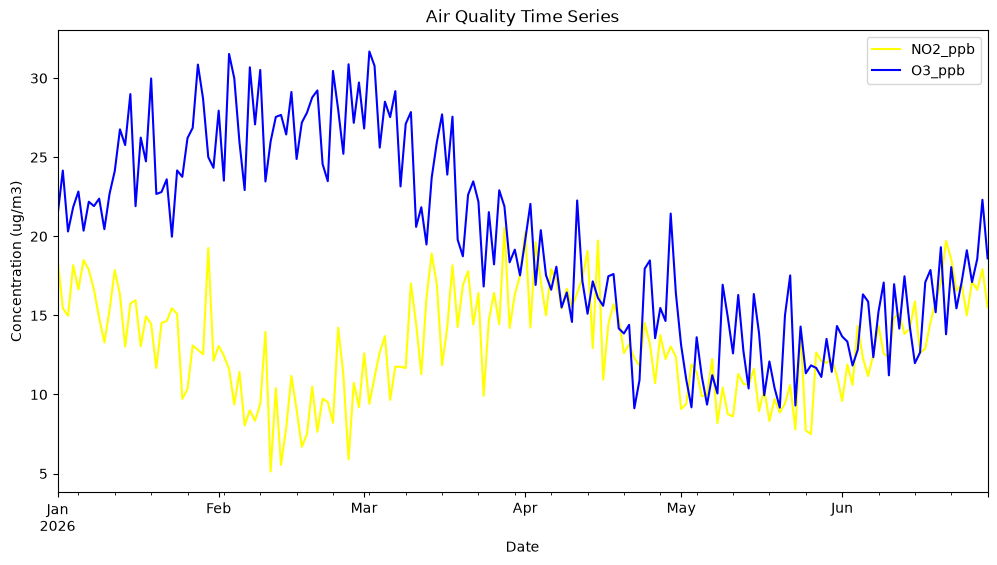

In [18]:
aq[["NO2_ppb", "O3_ppb"]].plot(
    kind="line",
    figsize=(12, 6),
    title="Air Quality Time Series",
    xlabel="Date",
    ylabel="Concentration (ug/m3)",
    legend=True,
    color=["yellow", "blue"],
)

#### `.scatter()`

Text(0, 0.5, 'Temperature (°C)')

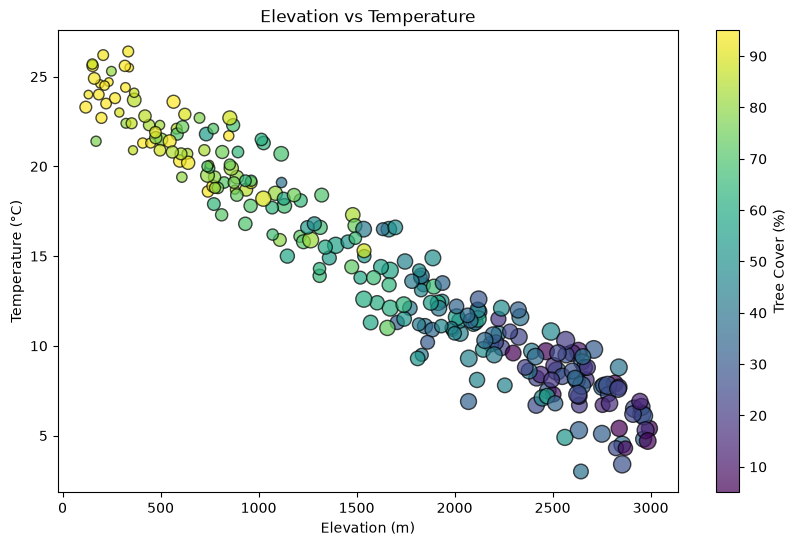

In [19]:
df = pd.read_csv("data/environmental_scatter.csv")

plt.figure(figsize=(10, 6))
scatter = plt.scatter(
    x=df["Elevation_m"],
    y=df["Temperature_C"],
    c=df["Tree_Cover_Pct"],  # Color mapping
    s=df["Annual_Rainfall_mm"] / 10,  # Size mapping
    alpha=0.7,
    edgecolor="black",
    cmap="viridis",
    marker="o",
)
plt.colorbar(scatter, label="Tree Cover (%)")
plt.title("Elevation vs Temperature")
plt.xlabel("Elevation (m)")
plt.ylabel("Temperature (°C)")

#### `.hist()`, `.kde()`

<Axes: title={'center': 'Soil pH Distribution'}, ylabel='Density'>

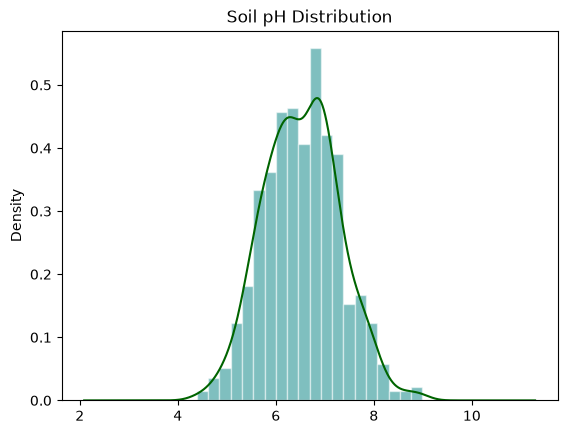

In [20]:
df = pd.read_csv("data/soil_measurements_hist_kde.csv")

# Example: Histogram + KDE overlay
ax = df["Soil_pH"].plot.hist(
    bins=20, density=True, alpha=0.5, color="teal", edgecolor="white"
)
df["Soil_pH"].plot.kde(
    ax=ax, color="darkgreen", bw_method="scott", title="Soil pH Distribution"
)

#### `.bar()`

<Axes: title={'center': 'Monthly Renewable Energy Generation by Region'}, xlabel='Month', ylabel='Energy (GWh)'>

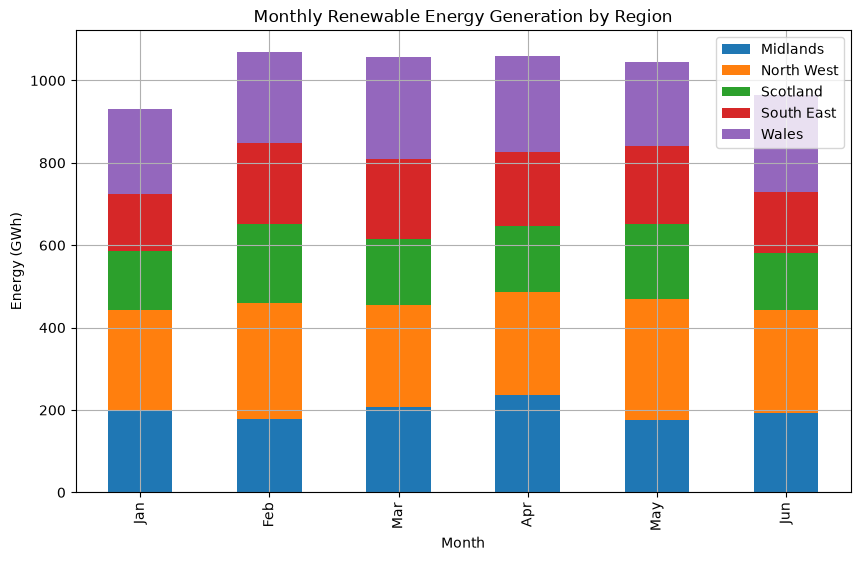

In [21]:
df = pd.read_csv("data/renewable_energy_bar.csv", index_col="Month")

# Example: Vertical stacked bar plot with custom styling
df.plot.bar(
    figsize=(10, 6),
    stacked=True,
    title="Monthly Renewable Energy Generation by Region",
    ylabel="Energy (GWh)",
    grid=True,
)

#### `.boxplot()`

Text(0, 0.5, 'Dissolved Oxygen (mg/L)')

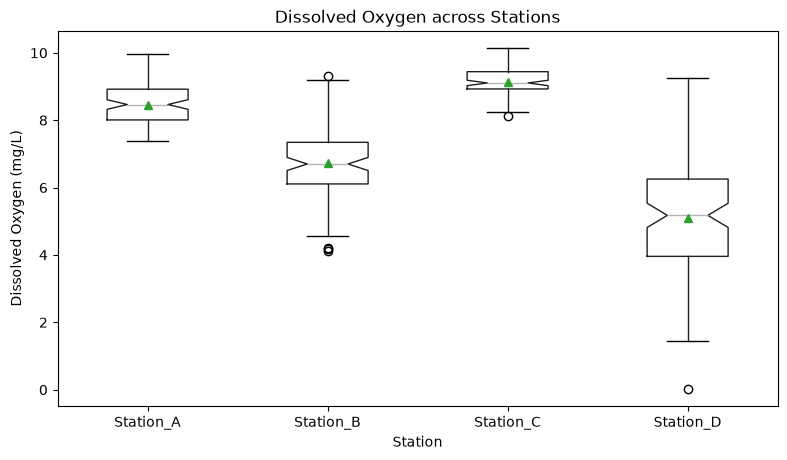

In [22]:
df = pd.read_csv("data/water_quality_boxplot.csv")

# Example: Grouped boxplot in pandas
df.boxplot(
    column="Dissolved_Oxygen_mgL",
    by="Station",
    vert=True,
    notch=True,
    showmeans=True,
    grid=False,
    figsize=(9, 5),
)
plt.title("Dissolved Oxygen across Stations")
plt.suptitle("")  # Suppress pandas default title
plt.ylabel("Dissolved Oxygen (mg/L)")